# Phase 2 — Explore the audio

Goal: build intuition before modelling. By the end you should be able to say, in plain words,
**how anger, sadness and neutral differ acoustically**, and **how TESS differs from RAVDESS**.

Sections:
1. What is inside one audio file
2. Controlled comparison of emotions (same speaker, same sentence)
3. The same comparison on TESS
4. Dataset-level statistics: sample rate, duration, silence, loudness
5. Which dataset do the Kaggle test clips look like?

Use headphones for the listening cells.

In [1]:
from pathlib import Path

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
from IPython.display import Audio, display
from tqdm.auto import tqdm

ROOT = Path('..')  # notebooks run from the notebooks/ folder
meta = pd.read_csv(ROOT / 'data/preprocessed/metadata.csv')
test_meta = pd.read_csv(ROOT / 'data/preprocessed/test_metadata.csv')
meta.head()

/Users/shardjosh19/Code/audio-project-kaggle/audio-kagcomp/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,path,dataset,speaker,gender,emotion,intensity,text,repetition,label
0,data/raw/ravdess/Actor_01/03-01-01-01-01-01-01...,ravdess,ravdess_01,male,neutral,normal,kids,1,neutral
1,data/raw/ravdess/Actor_01/03-01-01-01-01-02-01...,ravdess,ravdess_01,male,neutral,normal,kids,2,neutral
2,data/raw/ravdess/Actor_01/03-01-01-01-02-01-01...,ravdess,ravdess_01,male,neutral,normal,dogs,1,neutral
3,data/raw/ravdess/Actor_01/03-01-01-01-02-02-01...,ravdess,ravdess_01,male,neutral,normal,dogs,2,neutral
4,data/raw/ravdess/Actor_01/03-01-02-01-01-01-01...,ravdess,ravdess_01,male,calm,normal,kids,1,NaN


In [32]:
meta.shape, test_meta.shape

((4240, 9), (201, 2))

## 1. What is inside one audio file

`librosa.load(path, sr=None)` returns two things:
- `y`: a 1-D array of **samples**, the air-pressure readings, scaled to the range -1..1
- `sr`: the **sample rate**, how many samples per second

`sr=None` keeps the file's native rate. Without it, librosa silently resamples to 22,050 Hz.

In [15]:
clip = meta.query("dataset == 'ravdess' and speaker == 'ravdess_01' and emotion == 'angry' "
                  "and intensity == 'strong' and text == 'kids' and repetition == 1").iloc[0]
y, sr = librosa.load(ROOT / clip.path, sr=None)

print(f'file         : {clip.path}')
print(f'sample rate  : {sr} Hz')
print(f'num samples  : {len(y):,}')
print(f'duration     : {len(y) / sr:.2f} s')
print(f'dtype, range : {y.dtype}, [{y.min():.3f}, {y.max():.3f}]')
display(Audio(y, rate=sr))

file         : data/raw/ravdess/Actor_01/03-01-05-02-01-01-01.wav
sample rate  : 48000 Hz
num samples  : 196,997
duration     : 4.10 s
dtype, range : float32, [-0.796, 0.818]


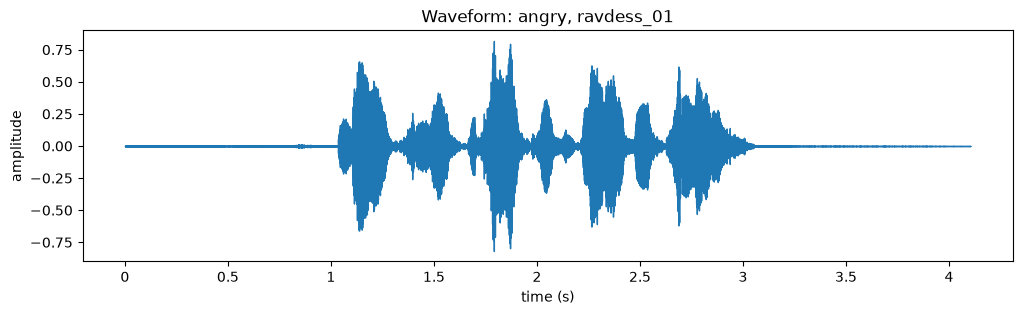

In [3]:
fig, ax = plt.subplots(figsize=(12, 3))
librosa.display.waveshow(y, sr=sr, ax=ax)
ax.set(title=f'Waveform: {clip.emotion}, {clip.speaker}', xlabel='time (s)', ylabel='amplitude')
plt.show()

**Look for:** the flat stretches at the start and end are silence. The speech itself is
shorter than the file. Phase 3 will trim this silence, because it carries no emotion.

## 2. Controlled comparison: one speaker, one sentence, four emotions

To see what emotion changes, we hold everything else fixed: same actor, same sentence,
same repetition. Only the emotion varies.

Each row shows a **log-mel spectrogram** (time × frequency, colour = energy in dB)
with the **pitch contour (F0)** drawn in cyan on top. F0 is the fundamental frequency of
the voice, which we hear as pitch. It's estimated with `librosa.pyin`.

In [4]:
SR = 22050  # one common rate for all comparisons

def load(path):
    """This function loads an audio file and resamples it to a common sample rate (SR). Now we have an actual audio signal (instance) to work with."""
    y, _ = librosa.load(ROOT / path, sr=SR)
    return y

def pitch(y):
    # This needs to be understood
    f0, voiced, _ = librosa.pyin(y, sr=SR, fmin=librosa.note_to_hz('C2'), fmax=librosa.note_to_hz('C7'))
    return f0  # NaN where there is no voiced speech

def plot_emotions(rows, title):
    fig, axes = plt.subplots(len(rows), 1, figsize=(12, 3 * len(rows)), sharex=True)
    summary = []
    for ax, (_, r) in zip(axes, rows.iterrows()):
        y = load(r.path)
        # This needs to be understood
        mel_db = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=SR, n_mels=128), ref=np.max)
        f0 = pitch(y)
        rms_db = librosa.amplitude_to_db(librosa.feature.rms(y=y)[0])
        librosa.display.specshow(mel_db, sr=SR, x_axis='time', y_axis='mel', ax=ax, fmax=8000)
        ax.plot(librosa.times_like(f0, sr=SR), f0, color='cyan', linewidth=2)
        ax.set(title=r.emotion, xlabel='')
        summary.append({'emotion': r.emotion, 'duration_s': len(y) / SR,
                        'f0_mean_hz': np.nanmean(f0), 'f0_std_hz': np.nanstd(f0),
                        'loudness_db': rms_db.mean()})
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
    return pd.DataFrame(summary).round(1)

EMOTIONS = ['neutral', 'angry', 'happy', 'sad']
ravdess_rows = (meta.query("speaker == 'ravdess_01' and text == 'kids' and repetition == 1 "
                           "and (intensity == 'strong' or emotion == 'neutral')")
                    .set_index('emotion').loc[EMOTIONS].reset_index())

for _, r in ravdess_rows.iterrows():
    print(r.emotion)
    display(Audio(load(r.path), rate=SR))

neutral


angry


happy


sad


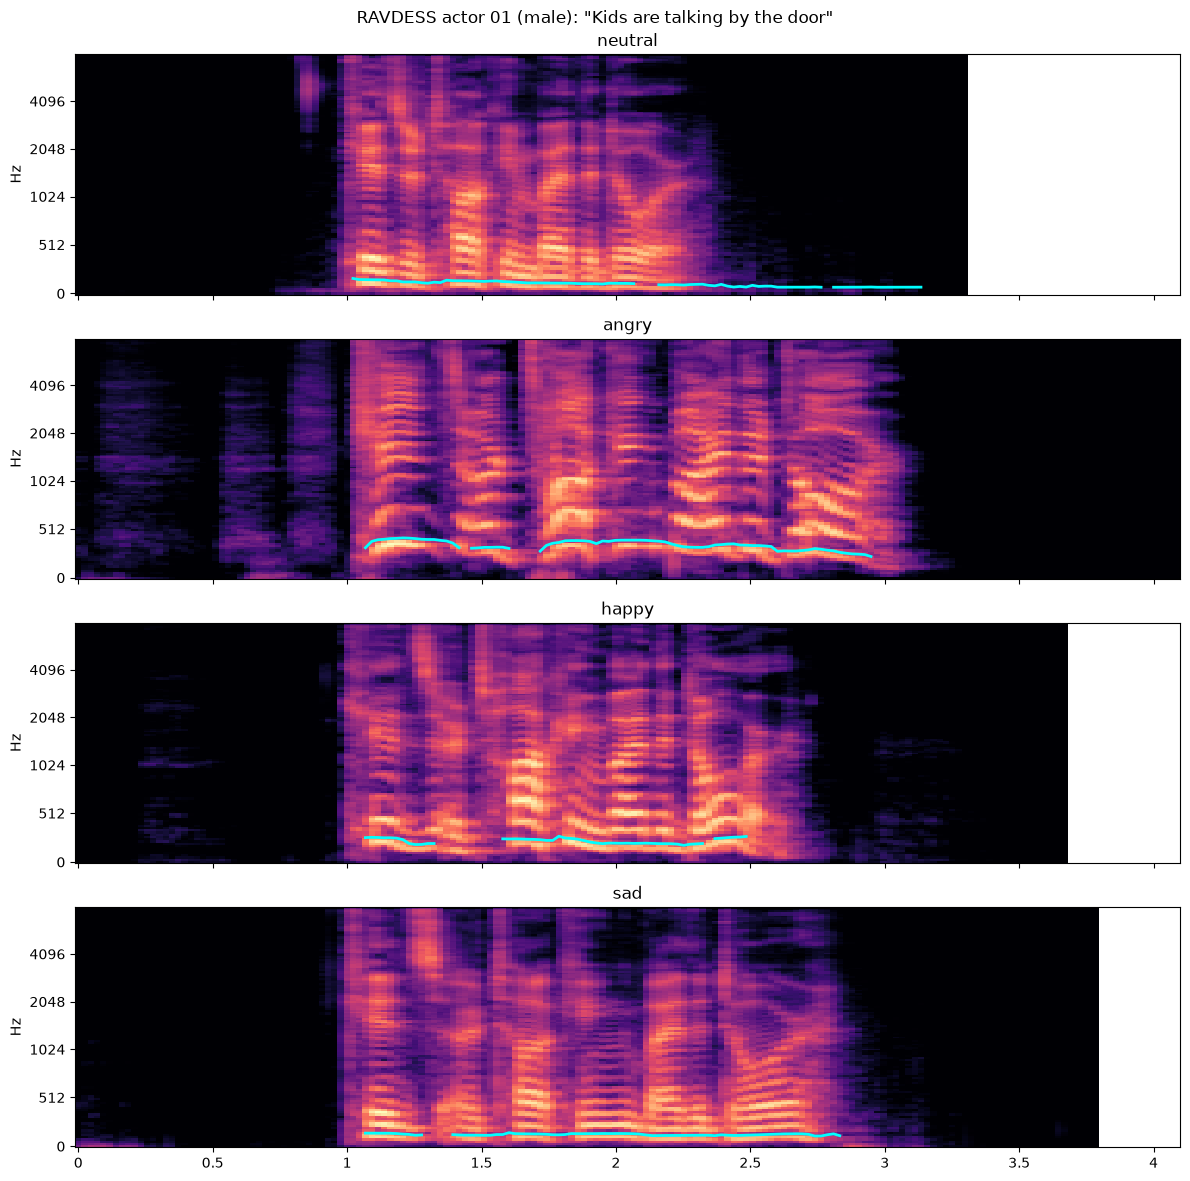

,emotion,duration_s,f0_mean_hz,f0_std_hz,loudness_db
0,neutral,3.3,98.4,26.6,-76.000000
1,angry,4.1,343.2,48.9,-47.700001
2,happy,3.7,221.5,28.8,-68.599998
3,sad,3.8,123.6,8.6,-70.800003


In [5]:
plot_emotions(ravdess_rows, 'RAVDESS actor 01 (male): "Kids are talking by the door"')

**Questions to answer from the plots, the table and your ears:**
- Which emotion has the highest pitch? Which has the most *varied* pitch (`f0_std_hz`)?
- Which is loudest? Where in the spectrogram does extra energy show up for anger
  (low or high frequencies)?
- Is sad speech slower (longer duration) than neutral?
- Try another actor (e.g. `ravdess_02`, female). Do the same patterns hold?

**Answers to questions above:**
- The emotion with the highest pitch is '_angry_'. The most varied emotion is also '_angry_' in this example.
- The loudest in this example is '_angry_'. The extra energy for angry emotion is shown in the higher frequencies.
- In this example, yes, the sad emotion is longer than neutral by almost 0.5s.
- Tried below:


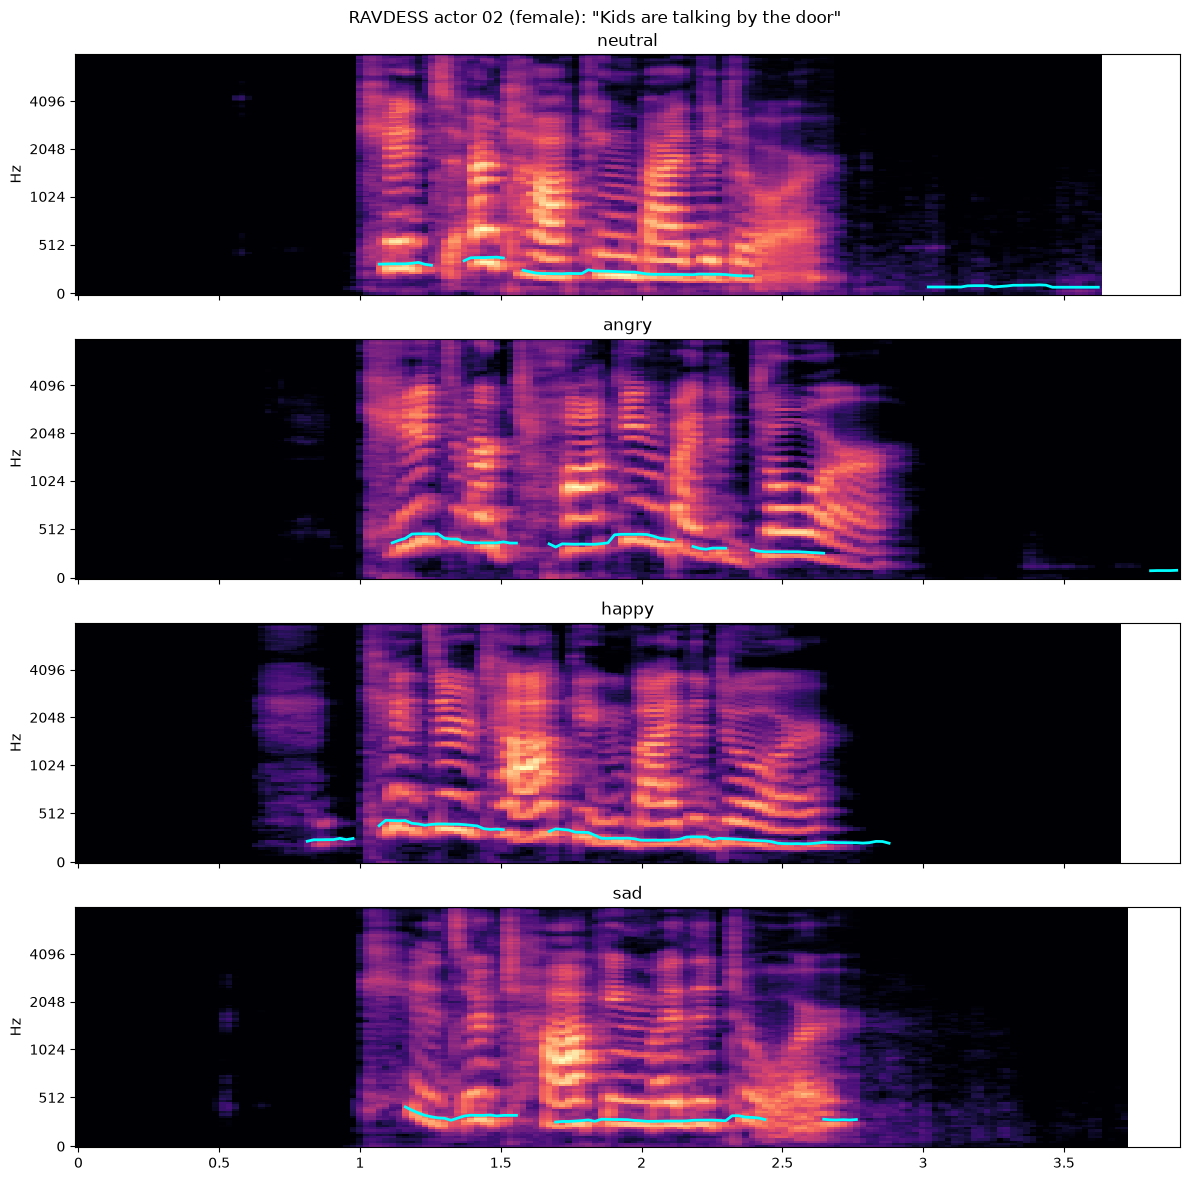

,emotion,duration_s,f0_mean_hz,f0_std_hz,loudness_db
0,neutral,3.6,189.5,97.5,-71.400002
1,angry,3.9,339.6,98.9,-58.500000
2,happy,3.7,276.0,75.3,-61.900002
3,sad,3.7,291.4,31.0,-73.099998


In [16]:
# Taking a random female actor from RAVDESS

ravdess_rows = (meta.query("speaker == 'ravdess_02' and text == 'kids' and repetition == 1 "
                           "and (intensity == 'strong' or emotion == 'neutral')")
                    .set_index('emotion').loc[EMOTIONS].reset_index())



plot_emotions(ravdess_rows, 'RAVDESS actor 02 (female): "Kids are talking by the door"')

## 3. The same comparison on TESS

Same idea: one speaker, one word, four emotions. TESS clips are one carrier phrase,
"Say the word ___", so they're shorter.

neutral


angry


happy


sad


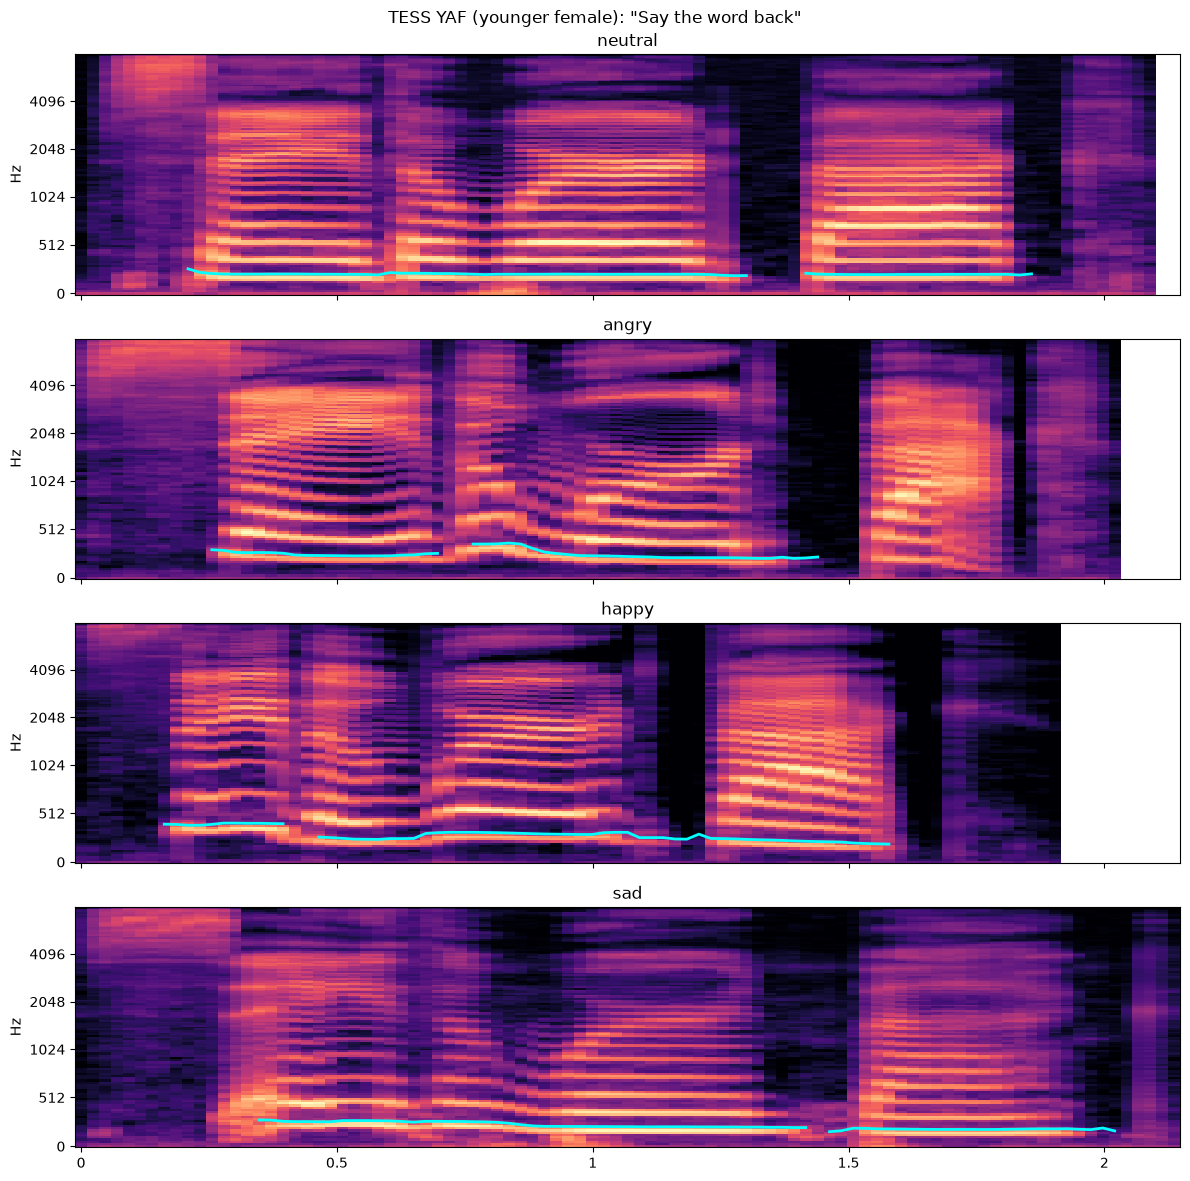

,emotion,duration_s,f0_mean_hz,f0_std_hz,loudness_db
0,neutral,2.1,202.9,8.8,-35.599998
1,angry,2.0,246.4,43.6,-32.200001
2,happy,1.9,284.9,64.0,-30.200001
3,sad,2.1,212.6,34.9,-32.700001


In [17]:
tess_rows = (meta.query("speaker == 'tess_YAF' and text == 'back'")
                 .set_index('emotion').loc[EMOTIONS].reset_index())

for _, r in tess_rows.iterrows():
    print(r.emotion)
    display(Audio(load(r.path), rate=SR))

plot_emotions(tess_rows, 'TESS YAF (younger female): "Say the word back"')

**Questions:** are the emotion patterns the same as in RAVDESS? How different do the two
*datasets* sound: recording quality, background noise, acting style?

**Answers to questions above:**
- The emotion patterns are completely different for the two datasets in terms of frequency, the sentences, the duration of the speech. One observation is the energy is higher on the starting of the speech for the TESS dataset indicating background noise. RAVDESS dataset has much better recording quality.


## 4. Dataset-level statistics

Now we look at every file. For each clip we record:
- `sample_rate`, `channels`, `duration_s`: read from the file header with `soundfile.info`,
  which is fast because no audio is decoded
- `speech_s`: duration after trimming leading and trailing silence (`librosa.effects.trim`)
- `silence_frac`: the fraction of the file that is leading or trailing silence
- `loudness_db`: average RMS energy of the trimmed speech, in dB

Loading about 4,400 files takes a minute or two. Results are cached to
`data/preprocessed/audio_stats.csv`, so this only runs once.

In [18]:
STATS_PATH = ROOT / 'data/preprocessed/audio_stats.csv'

def audio_stats(path):
    # What is happening here? Why is this needed?
    info = sf.info(ROOT / path)
    y, sr = librosa.load(ROOT / path, sr=None)
    speech, _ = librosa.effects.trim(y, top_db=30)
    return {'sample_rate': info.samplerate, 'channels': info.channels,
            'duration_s': info.duration, 'speech_s': len(speech) / sr,
            'silence_frac': 1 - len(speech) / len(y),
            'loudness_db': float(librosa.amplitude_to_db(librosa.feature.rms(y=speech)[0]).mean())}

if STATS_PATH.exists():
    stats = pd.read_csv(STATS_PATH)
else:
    files = pd.concat([meta[['path', 'dataset']], test_meta[['path']].assign(dataset='kaggle_test')])
    stats = pd.DataFrame([{'path': p, 'dataset': d, **audio_stats(p)}
                          for p, d in tqdm(zip(files.path, files.dataset), total=len(files))])
    stats.to_csv(STATS_PATH, index=False)

stats.groupby('dataset')[['duration_s', 'speech_s', 'silence_frac', 'loudness_db']].describe().T.round(2)

dataset             kaggle_test  ravdess     tess
duration_s   count       201.00  1440.00  2800.00
             mean          2.70     3.70     2.06
             std           0.88     0.34     0.32
             min           1.30     2.94     1.25
             25%           2.02     3.47     1.84
             50%           2.34     3.67     2.05
             75%           3.54     3.87     2.28
             max           4.94     5.27     2.98
speech_s     count       201.00  1440.00  2800.00
             mean          1.95     1.84     1.98
             std           0.38     0.43     0.33
             min           1.25     1.07     1.22
             25%           1.64     1.55     1.76
             50%           1.95     1.74     1.99
             75%           2.16     2.06     2.20
             max           3.26     4.26     2.96
silence_frac count       201.00  1440.00  2800.00
             mean          0.21     0.51     0.04
             std           0.23     0.09     0.04
             min           0.00     0.00     0.00
             25%           0.02     0.48     0.01
             50%           0.06     0.53     0.02
             75%           0.50     0.56     0.05
             max           0.61     0.65     0.24
loudness_db  count       201.00  1440.00  2800.00
             mean        -37.02   -41.90   -34.49
             std           7.26     9.53     4.85
             min         -65.23   -74.81   -45.19
             25%         -41.13   -47.93   -38.26
             50%         -36.36   -42.15   -34.41
             75%         -32.19   -35.41   -31.09
             max         -20.91   -19.04   -20.91

In [19]:
print('Sample rates:')
print(pd.crosstab(stats.sample_rate, stats.dataset), '\n')
print('Channels:')
print(pd.crosstab(stats.channels, stats.dataset))

Sample rates:
dataset      kaggle_test  ravdess  tess
sample_rate                            
16000                 80        0     0
24414                121        0  2799
48000                  0     1440     0
96000                  0        0     1 

Channels:
dataset   kaggle_test  ravdess  tess
channels                            
1                 201     1435  2800
2                   0        5     0


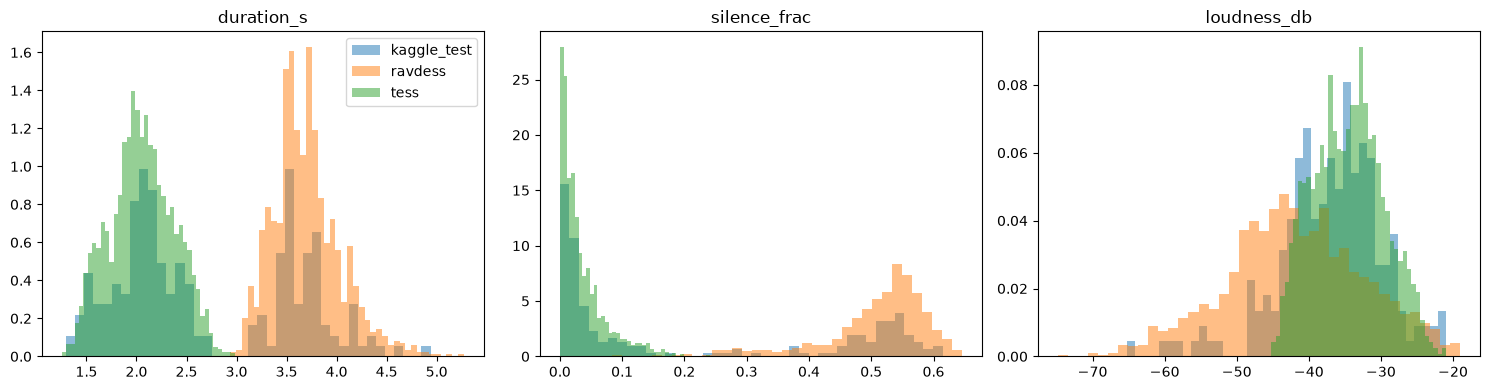

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for col, ax in zip(['duration_s', 'silence_frac', 'loudness_db'], axes):
    for name, group in stats.groupby('dataset'):
        ax.hist(group[col], bins=40, alpha=0.5, density=True, label=name)
    ax.set(title=col)
axes[0].legend()
plt.tight_layout()
plt.show()

**Questions:**
- Do the two datasets share a sample rate? What does that mean for preprocessing?
- Are any files stereo?
- How much of a typical RAVDESS file is silence, compared with TESS?
- If clip length, silence or loudness differ systematically between datasets, could a model
  use them as a shortcut to tell the datasets apart instead of learning emotion?

**Answers:**
- The sample rates for the 2 datasets are completely different (24k and 48k). I don't know what that means (explain it to me later).
- What is that again?
- Almost 50% of the RAVDESS file is silent. Better recording setup.
- No. I don't think so. The emotion should be irrelevant of the length or silence or loudness of the speech. This model would need better signal processing.

## 5. Which dataset do the Kaggle test clips look like?

The brief says the test set mixes TESS and RAVDESS clips. The sample rate in the file
header is a strong fingerprint of where a clip came from.

In [24]:
test_stats = stats.query("dataset == 'kaggle_test'").copy()
rates = {sr: name for name, sr in stats.query("dataset != 'kaggle_test'").groupby('dataset').sample_rate.first().items()}
test_stats['likely_source'] = test_stats.sample_rate.map(rates).fillna('unknown')
print(test_stats.likely_source.value_counts())
test_stats.groupby('likely_source')[['duration_s', 'loudness_db']].mean().round(2)

likely_source
tess       121
unknown     80
Name: count, dtype: int64


,duration_s,loudness_db
likely_source,,
tess,2.04,-34.81
unknown,3.70,-40.36


**Questions:** what is the TESS / RAVDESS mix in the test set? Does it match the mix in
training (69% TESS)? Listen to a couple of `unknown` clips if there are any.

---
### Checkpoint (end of Phase 2)
Write 3–5 sentences in your own words, in a markdown cell below:
1. How anger, sadness and neutral differ in pitch, loudness and speed.
2. How TESS and RAVDESS differ as recordings.
3. What the test set is made of.
4. What this means for Phase 3 preprocessing.

In [28]:
stats_emotion  = stats.merge(meta[['path', 'emotion']], on='path', how='left')
stats_emotion

,path,dataset,sample_rate,channels,duration_s,speech_s,silence_frac,loudness_db,emotion
0,data/raw/ravdess/Actor_01/03-01-01-01-01-01-01...,ravdess,48000,1,3.303292,1.429333,0.567300,-50.869389,neutral
1,data/raw/ravdess/Actor_01/03-01-01-01-01-02-01...,ravdess,48000,1,3.336667,1.312000,0.606793,-47.275360,neutral
2,data/raw/ravdess/Actor_01/03-01-01-01-02-01-01...,ravdess,48000,1,3.269917,1.280000,0.608553,-45.208233,neutral
3,data/raw/ravdess/Actor_01/03-01-01-01-02-02-01...,ravdess,48000,1,3.169833,1.216000,0.616384,-45.657791,neutral
4,data/raw/ravdess/Actor_01/03-01-02-01-01-01-01...,ravdess,48000,1,3.536854,1.568000,0.556668,-51.838722,calm
...,...,...,...,...,...,...,...,...,...
4436,data/raw/kaggle_test/MP4_Kaggle_Testset/MP4_Ka...,kaggle_test,16000,1,3.269938,1.344000,0.588983,-45.936863,NaN
4437,data/raw/kaggle_test/MP4_Kaggle_Testset/MP4_Ka...,kaggle_test,24414,1,2.187352,2.097157,0.041234,-33.915222,NaN
4438,data/raw/kaggle_test/MP4_Kaggle_Testset/MP4_Ka...,kaggle_test,24414,1,2.524289,2.524289,0.000000,-41.014736,NaN
4439,data/raw/kaggle_test/MP4_Kaggle_Testset/MP4_Ka...,kaggle_test,24414,1,1.977308,1.971328,0.003024,-31.808378,NaN


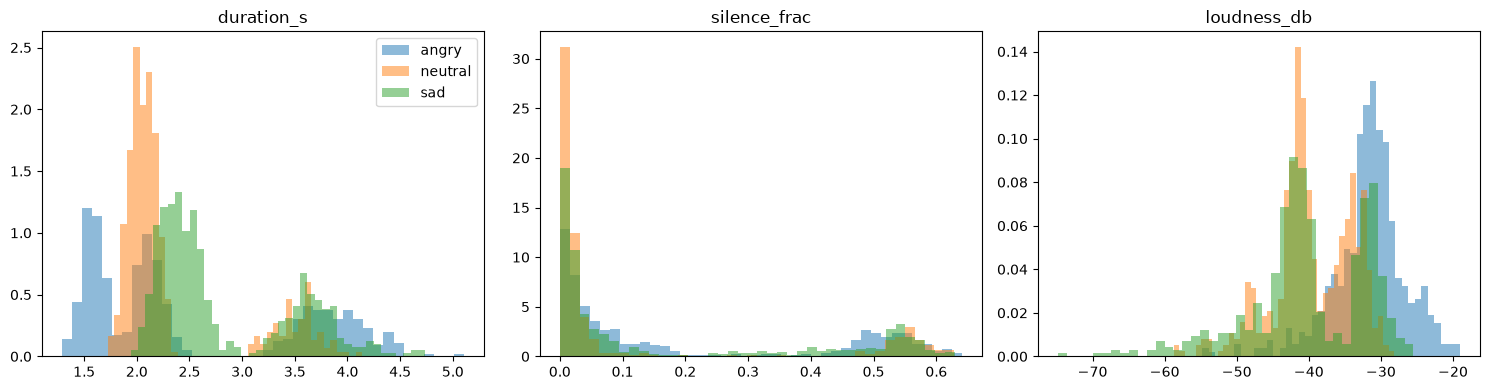

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for col, ax in zip(['duration_s', 'silence_frac', 'loudness_db'], axes):
    for name, group in stats_emotion[stats_emotion['emotion'].isin(['angry','neutral', 'sad'])].groupby('emotion'):
        ax.hist(group[col], bins=40, alpha=0.5, density=True, label=name)
    ax.set(title=col)
axes[0].legend()
plt.tight_layout()
plt.show()

#### Answers to pass the checkpoint:
1. Sad has the longest duration, neutral has least silence and angry is the loudest.
2. TESS dataset has more background noise in the recording.
3. The test is mainly TESS dataset.
4. We will have to normalize the data in Phase 3.